## To obtain the subconcepts of a given SNOMED CT concept

In [2]:
import networkx as nx

In [3]:
# specify input files
concept_labels_file = 'desktop/snomed_20220301_labels.txt'
concept_hierarchy_file = 'desktop/snomed_20220301_hierarchy.txt'

In [4]:
graph = nx.DiGraph()

# load SNOMED CT concepts to NetworkX graph
with open(concept_labels_file, 'r') as labels_file:
    for line in labels_file.readlines():
        concept_ID, concept_label = line.rstrip("\n").split("\t")
        graph.add_node(concept_ID, label=concept_label)
        
# load SNOMED CT hierarchical relations to NetworkX graph
with open(concept_hierarchy_file, 'r') as hierarchy_file:
    for line in hierarchy_file.readlines():
        child, parent = line.rstrip("\n").split("\t")
        graph.add_edge(parent, child)

In [5]:
# this method returns the subclasses of the class with the given concept_id.
def get_subclasses(concept_id):
    if concept_id not in graph.nodes():
        print('Concept not in this SNOMED CT version!!')
        return
    return nx.descendants(graph, concept_id)

In [6]:
concept_id = '123948009'     # concept id of which we need to find subclasses. e.g. 123948009 = "Disorder following viral disease (disorder)"
get_subclasses(concept_id)

{'106371000119109',
 '10698009',
 '110269000',
 '110270004',
 '111872008',
 '1119303003',
 '1119304009',
 '1144351000',
 '1144352007',
 '1144504001',
 '12551000132107',
 '12561000132105',
 '12571000132104',
 '127054006',
 '13420004',
 '138371000119104',
 '15678761000119105',
 '15678801000119102',
 '15678841000119100',
 '15680201000119106',
 '15680241000119108',
 '15680281000119103',
 '15681321000119100',
 '15681401000119101',
 '15685081000119102',
 '15685121000119100',
 '15685201000119100',
 '15685281000119108',
 '15989271000119107',
 '15989311000119107',
 '15989351000119108',
 '15992271000119100',
 '15992311000119100',
 '16015471000119102',
 '16015551000119107',
 '16015631000119102',
 '17974002',
 '186509002',
 '187260009',
 '191008001',
 '191727003',
 '192079006',
 '193190005',
 '203284001',
 '203286004',
 '203287008',
 '203288003',
 '203289006',
 '203291003',
 '203292005',
 '203294006',
 '2177002',
 '21954000',
 '230146001',
 '230188005',
 '230491004',
 '230536009',
 '230597003',
 '

In [7]:
# If needed, the name of a concept could be retrieved as follows.

conid = '106371000119109'
graph.nodes[conid]['label']

'Osteopathy co-occurrent and due to non active poliomyelitis of lower leg (disorder)'

## Final Project

Overview : The aim of this analysis is to help the state government of Maryland to identify where they could provide healthcare assistance to the older population. Due to budgetary constraints, they would
be unable to cover all the needs of each and every person, therefore this analysis will highlight the most significant areas for potential intervention.

This analysis uses the provided zip file ‘patient_data.zip’ contains data about 53,068 patients spread across 16 CSV files, which includes patient demographics, healthcare expenses, coverage, medications, immunizations, medical conditions, procedures, providers and payer information.

In [8]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime
import warnings
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, sum, avg, desc, year, to_date
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
pd.set_option('display.float_format', '{:.2f}'.format)

# Set visualization style
# plt.style.use('seaborn-whitegrid')
sns.set_palette('Set2')
warnings.filterwarnings('ignore')

# For better visualization in notebook
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

In [9]:
# Initialize Spark Session
spark = SparkSession.builder \
    .appName("Maryland Healthcare Analysis") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .getOrCreate()

print(f"Spark version: {spark.version}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/05/01 12:42:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.4


## Data loading and exploration

First, we will load the CSV files and perform initial exploration to understand the structure of the data.

In [10]:
# Define the data directory
data_dir = "desktop/patient_data"

# List all the CSV files in the directory
csv_files = [f for f in os.listdir(data_dir) if f.endswith('.csv')]
print(f"Found {len(csv_files)} CSV files in the data directory:")
for file in csv_files:
    print(f"- {file}")

Found 16 CSV files in the data directory:
- medications.csv
- providers.csv
- payer_transitions.csv
- imaging_studies.csv
- supplies.csv
- payers.csv
- allergies.csv
- procedures.csv
- organizations.csv
- conditions.csv
- careplans.csv
- encounters.csv
- devices.csv
- immunizations.csv
- patients.csv
- observations.csv


In [11]:
# Function to load CSV files with both pandas and PySpark
def load_data(filename):
    # Load with pandas for initial exploration
    file_path = os.path.join(data_dir, filename)
    df_pandas = pd.read_csv(file_path)
    
    # Load with PySpark for big data processing
    df_spark = spark.read.csv(file_path, header=True, inferSchema=True)
    
    return df_pandas, df_spark

# Dictionaries to store dataframes
pandas_dfs = {}
spark_dfs = {}

In [12]:
# Load the patients data - our primary focus
patients_pd, patients_spark = load_data("patients.csv")
pandas_dfs["patients"] = patients_pd
spark_dfs["patients"] = patients_spark

# Display basic information
print(f"Patients dataset shape: {patients_pd.shape}")
patients_pd.head()

Patients dataset shape: (53068, 15)


,Id,BIRTHDATE,DEATHDATE,PREFIX,SUFFIX,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,CITY,STATE,COUNTY,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
0,f1639046-ecb1-b409-21d3-85a7e8e23c81,8/31/57,NaN,Ms.,NaN,S,white,nonhispanic,F,Germantown Maryland US,Baltimore,Maryland,Baltimore city,59484.51,1455.08
1,f851859f-b0fe-8b36-9939-4276b96d302d,11/22/50,NaN,Mrs.,NaN,M,black,nonhispanic,F,Clarksburg Maryland US,Baltimore,Maryland,Baltimore city,239428.05,12764.06
2,00e22b7e-70ae-e926-e0f6-4f3d8e30d019,10/24/53,7/12/19,Mr.,NaN,S,black,nonhispanic,M,Oxon Hill Maryland US,Downsville,Maryland,Washington County,1345863.62,3951.81
3,8dacd569-fbab-2604-de56-9859571ba52d,1/30/64,NaN,Mr.,NaN,M,asian,hispanic,M,Lima Lima Province PE,Olney,Maryland,Montgomery County,1387577.33,3711.51
4,fc488d45-11b9-52d3-3c81-14dbd5dbc7dc,10/24/39,NaN,Mrs.,NaN,M,white,nonhispanic,F,Ellicott City Maryland US,Baltimore,Maryland,Baltimore city,85562.87,4717.97


In [13]:
# Load additional key datasets
datasets = ["encounters.csv", "conditions.csv", "procedures.csv", "medications.csv", 
            "payers.csv", "providers.csv"]

for dataset in datasets:
    file_name = dataset.split('.')[0]
    try:
        pandas_dfs[file_name], spark_dfs[file_name] = load_data(dataset)
        print(f"Loaded {dataset}: {pandas_dfs[file_name].shape} rows")
    except Exception as e:
        print(f"Error loading {dataset}: {e}")

25/05/01 12:43:05 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


Loaded encounters.csv: (4875211, 15) rows


Loaded conditions.csv: (781304, 6) rows


Loaded procedures.csv: (2173780, 9) rows


Loaded medications.csv: (6855527, 13) rows
Loaded payers.csv: (10, 21) rows
Loaded providers.csv: (6749, 12) rows


## Data preprocessing

Now, we will preprocess the data to focus on the elderly population and prepare the datasets for analysis.

In [14]:
# Calculate age for each patient
# Current date for comparison
today = datetime.today()

# define custom function to calculate age
def calculate_age(birthdate_str):
    # Handle 2-digit year formatting (assuming 00-24 is 2000s, others 1900s)
    birthdate = datetime.strptime(birthdate_str, "%m/%d/%y")
    if birthdate.year > today.year:
        birthdate = birthdate.replace(year=birthdate.year - 100)
    
    age = today.year - birthdate.year
    # Adjust if birthday hasn't occurred yet this year
    if (today.month, today.day) < (birthdate.month, birthdate.day):
        age -= 1
    return age

In [15]:
# Apply the function to the BIRTHDATE column
patients_pd['AGE'] = patients_pd['BIRTHDATE'].apply(calculate_age)

# Convert BIRTHDATE to datetime and calculate age
#patients_pd['BIRTHDATE'] = pd.to_datetime(patients_pd['BIRTHDATE'], errors='coerce')

# Display the updated DataFrame
print(patients_pd.head(10))

                                     Id BIRTHDATE DEATHDATE PREFIX SUFFIX MARITAL   RACE    ETHNICITY GENDER                   BIRTHPLACE           CITY     STATE                  COUNTY  \
0  f1639046-ecb1-b409-21d3-85a7e8e23c81   8/31/57       NaN    Ms.    NaN       S  white  nonhispanic      F     Germantown  Maryland  US      Baltimore  Maryland          Baltimore city   
1  f851859f-b0fe-8b36-9939-4276b96d302d  11/22/50       NaN   Mrs.    NaN       M  black  nonhispanic      F     Clarksburg  Maryland  US      Baltimore  Maryland          Baltimore city   
2  00e22b7e-70ae-e926-e0f6-4f3d8e30d019  10/24/53   7/12/19    Mr.    NaN       S  black  nonhispanic      M      Oxon Hill  Maryland  US     Downsville  Maryland       Washington County   
3  8dacd569-fbab-2604-de56-9859571ba52d   1/30/64       NaN    Mr.    NaN       M  asian     hispanic      M      Lima  Lima Province  PE          Olney  Maryland       Montgomery County   
4  fc488d45-11b9-52d3-3c81-14dbd5dbc7dc  10/24/39 

In [16]:
# Filter for elderly population (65 years and older)
elderly_patients_pd = patients_pd[patients_pd['AGE'] >= 65].copy()
print(f"Total patients: {len(patients_pd)}")
print(f"Elderly patients (65+): {len(elderly_patients_pd)} ({len(elderly_patients_pd)/len(patients_pd)*100:.1f}%)")

Total patients: 53068
Elderly patients (65+): 39070 (73.6%)


In [17]:
# Register temporary view for SparkSQL

from pyspark.sql.functions import col, current_date, months_between, floor, to_date, when, expr

# Step 1: Convert to Date
patients_spark = patients_spark.withColumn("BIRTHDATE", to_date(col("BIRTHDATE"), "M/d/yy"))

# Step 2: Adjust future dates by subtracting 100 years
patients_spark = patients_spark.withColumn(
    "BIRTHDATE_CORRECTED",
    when(col("BIRTHDATE") > current_date(), expr("add_months(BIRTHDATE, -1200)"))  # 100 years = 1200 months
    .otherwise(col("BIRTHDATE"))
)

# Step 3: Calculate age using corrected birthdate
patients_spark = patients_spark.withColumn(
    "AGE",
    floor(months_between(current_date(), col("BIRTHDATE_CORRECTED")) / 12)
)

In [18]:
# Show the result
patients_spark.select("BIRTHDATE", "BIRTHDATE_CORRECTED", "AGE").show()

+----------+-------------------+---+
| BIRTHDATE|BIRTHDATE_CORRECTED|AGE|
+----------+-------------------+---+
|2057-08-31|         1957-08-31| 67|
|2050-11-22|         1950-11-22| 74|
|2053-10-24|         1953-10-24| 71|
|2064-01-30|         1964-01-30| 61|
|2039-10-24|         1939-10-24| 85|
|2028-11-09|         1928-11-09| 96|
|2057-01-11|         1957-01-11| 68|
|2041-05-07|         1941-05-07| 83|
|2023-02-02|         2023-02-02|  2|
|2058-07-28|         1958-07-28| 66|
|2063-08-20|         1963-08-20| 61|
|2053-10-24|         1953-10-24| 71|
|2044-05-21|         1944-05-21| 80|
|2027-03-25|         1927-03-25| 98|
|2023-02-02|         2023-02-02|  2|
|2064-02-17|         1964-02-17| 61|
|2034-03-16|         1934-03-16| 91|
|2041-05-07|         1941-05-07| 83|
|2038-11-01|         1938-11-01| 86|
|2029-12-31|         1929-12-31| 95|
+----------+-------------------+---+
only showing top 20 rows



In [19]:
elderly_patients_spark = patients_spark.filter(col("AGE") >= 65)
elderly_patients_spark.createOrReplaceTempView("elderly_patients")

In [20]:
# Basic statistics for healthcare expenses and coverage among elderly
expense_stats = elderly_patients_pd[['HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE']].describe()
print("Healthcare Financial Statistics for Elderly Patients:")
expense_stats

Healthcare Financial Statistics for Elderly Patients:


,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
count,39070.00,39070.00
mean,1274091.44,22135.69
std,510948.17,53364.70
min,1009.79,0.00
25%,1296213.39,5261.23
50%,1454950.35,8594.16
75%,1578480.92,14047.81
max,2323863.09,643931.21


In [21]:
# Calculate the gap between expenses and coverage
elderly_patients_pd['COVERAGE_GAP'] = elderly_patients_pd['HEALTHCARE_EXPENSES'] - elderly_patients_pd['HEALTHCARE_COVERAGE']
elderly_patients_pd['COVERAGE_RATIO'] = elderly_patients_pd['HEALTHCARE_COVERAGE'] / elderly_patients_pd['HEALTHCARE_EXPENSES']

# Summary of coverage gaps
coverage_gap_stats = elderly_patients_pd[['COVERAGE_GAP', 'COVERAGE_RATIO']].describe()
print("Coverage Gap Statistics for Elderly Patients:")
coverage_gap_stats

Coverage Gap Statistics for Elderly Patients:


,COVERAGE_GAP,COVERAGE_RATIO
count,39070.00,39070.00
mean,1251955.75,0.03
std,509281.31,0.20
min,-406809.03,0.00
25%,1263203.46,0.00
50%,1433132.25,0.01
75%,1557154.36,0.01
max,2164737.04,10.42


## Analysis of healthcare needs for older population

Now, we will analyze the specific healthcare needs of the elderly population, focusing on common conditions, expenses, and coverage gaps.

In [22]:
# Join elderly patients with conditions to find most common conditions
if 'conditions' in spark_dfs:
    # Get patient IDs of elderly patients
    elderly_ids = set(elderly_patients_pd['Id'])
    
    # Filter conditions for elderly patients
    elderly_conditions = pandas_dfs['conditions'][pandas_dfs['conditions']['PATIENT'].isin(elderly_ids)]
    
    # Count occurrences of each condition
    condition_counts = elderly_conditions['DESCRIPTION'].value_counts().reset_index()
    condition_counts.columns = ['Condition', 'Count']
    
    # Display top conditions
    print("Top 10 Most Common Conditions Among Elderly:")
    display(condition_counts.head(10))
    
    # Using PySpark for larger scale analysis
    spark_dfs['conditions'].createOrReplaceTempView("conditions")
    
    elderly_conditions_spark = spark.sql("""
        SELECT c.CODE, c.DESCRIPTION, COUNT(*) as count
        FROM conditions c
        JOIN elderly_patients ep ON c.PATIENT = ep.Id
        GROUP BY c.CODE, c.DESCRIPTION
        ORDER BY count DESC
        LIMIT 10
    """)
    
    print("\nTop Conditions (Using Spark SQL):")
    elderly_conditions_spark.show(truncate=False)


Top 10 Most Common Conditions Among Elderly:


,Condition,Count
0,Viral sinusitis (disorder),43745
1,Acute viral pharyngitis (disorder),24046
2,Body mass index 30+ - obesity (finding),23089
3,Suspected COVID-19,20414
4,Prediabetes,20396
5,COVID-19,19994
6,Acute bronchitis (disorder),19866
7,Anemia (disorder),19050
8,Fever (finding),18270
9,Cough (finding),13931



Top Conditions (Using Spark SQL):


+---------+---------------------------------------+-----+
|CODE     |DESCRIPTION                            |count|
+---------+---------------------------------------+-----+
|444814009|Viral sinusitis (disorder)             |45400|
|195662009|Acute viral pharyngitis (disorder)     |24936|
|162864005|Body mass index 30+ - obesity (finding)|23932|
|15777000 |Prediabetes                            |21167|
|840544004|Suspected COVID-19                     |20830|
|10509002 |Acute bronchitis (disorder)            |20565|
|840539006|COVID-19                               |20404|
|271737000|Anemia (disorder)                      |19750|
|386661006|Fever (finding)                        |18643|
|49727002 |Cough (finding)                        |14220|
+---------+---------------------------------------+-----+



In [23]:
# Analyze medications for elderly patients
if 'medications' in spark_dfs:
    spark_dfs['medications'].createOrReplaceTempView("medications")
    
    # Top medications prescribed to elderly
    elderly_medications = spark.sql("""
        SELECT m.DESCRIPTION, COUNT(*) as count, AVG(m.BASE_COST) as avg_cost,
               AVG(m.PAYER_COVERAGE) as avg_coverage,
               AVG(m.BASE_COST - m.PAYER_COVERAGE) as avg_out_of_pocket
        FROM medications m
        JOIN elderly_patients ep ON m.PATIENT = ep.Id
        GROUP BY m.DESCRIPTION
        ORDER BY count DESC
        LIMIT 15
    """)
    
    print("Top Medications for Elderly Patients:")
    elderly_medications.show(truncate=False)

Top Medications for Elderly Patients:


+----------------------------------------------------------------------------------------------------+------+--------------------+------------------+--------------------+
|DESCRIPTION                                                                                         |count |avg_cost            |avg_coverage      |avg_out_of_pocket   |
+----------------------------------------------------------------------------------------------------+------+--------------------+------------------+--------------------+
|Hydrochlorothiazide 25 MG Oral Tablet                                                               |688974|0.008587566439367094|0.0               |0.008587566439367094|
|lisinopril 10 MG Oral Tablet                                                                        |685537|0.009999999999993656|0.0               |0.009999999999993656|
|amLODIPine 2.5 MG Oral Tablet                                                                       |588357|0.017292069270858027|0.0            

In [24]:
# Analyze procedures for elderly patients
if 'procedures' in spark_dfs:
    spark_dfs['procedures'].createOrReplaceTempView("procedures")
    
    # Top procedures for elderly
    elderly_procedures = spark.sql("""
        SELECT p.DESCRIPTION, COUNT(*) as count, AVG(p.BASE_COST) as avg_cost
        FROM procedures p
        JOIN elderly_patients ep ON p.PATIENT = ep.Id
        GROUP BY p.DESCRIPTION
        ORDER BY avg_cost DESC
        LIMIT 15
    """)
    
    print("Most Expensive Procedures for Elderly Patients:")
    elderly_procedures.show(truncate=False)

Most Expensive Procedures for Elderly Patients:


+-----------------------------------------------------------------+------+------------------+
|DESCRIPTION                                                      |count |avg_cost          |
+-----------------------------------------------------------------+------+------------------+
|Lung Transplant                                                  |1     |514984.44         |
|Admit to ICU (procedure)                                         |555   |264601.8474774775 |
|Transplant of lung (procedure)                                   |144   |175841.81583333336|
|Radiation oncology AND/OR radiotherapy (procedure)               |1048  |169461.00794847327|
|Coronary artery bypass grafting                                  |2381  |45222.915186896265|
|Lung volume reduction surgery (procedure)                        |176   |34829.35892045454 |
|Construction of diverting colostomy                              |20    |31598.747499999998|
|Lumpectomy of breast (procedure)                           

## Visualizing healthcare coverage gaps

Now, we will create visualizations to better understand the healthcare coverage gaps for elderly patients.

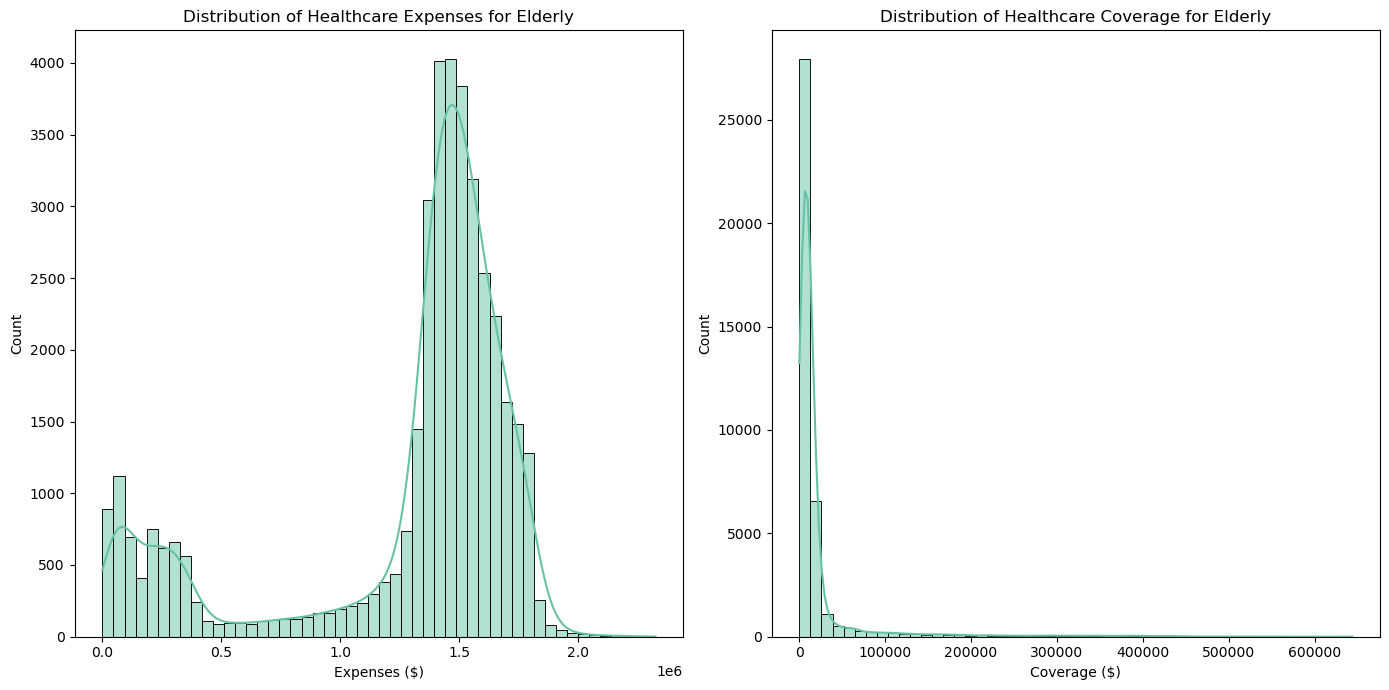

In [25]:
# Create histograms of healthcare expenses and coverage
plt.figure(figsize=(14, 7))

# Plot healthcare expenses
plt.subplot(1, 2, 1)
sns.histplot(elderly_patients_pd['HEALTHCARE_EXPENSES'], bins=50, kde=True)
plt.title('Distribution of Healthcare Expenses for Elderly')
plt.xlabel('Expenses ($)')
plt.ylabel('Count')

# Plot healthcare coverage
plt.subplot(1, 2, 2)
sns.histplot(elderly_patients_pd['HEALTHCARE_COVERAGE'], bins=50, kde=True)
plt.title('Distribution of Healthcare Coverage for Elderly')
plt.xlabel('Coverage ($)')

plt.tight_layout()
plt.show()

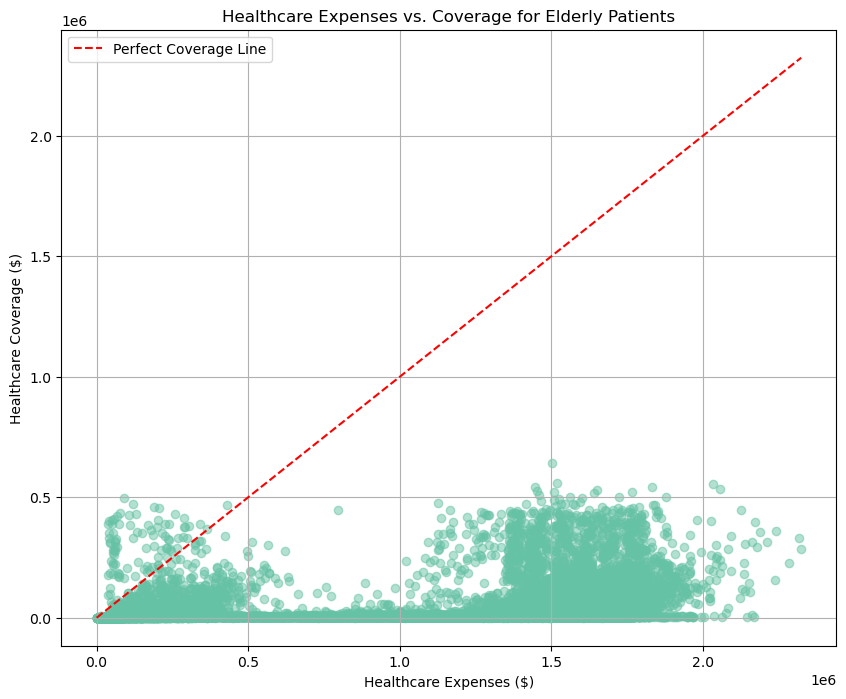

In [26]:
# Create scatterplot of expenses vs. coverage
plt.figure(figsize=(10, 8))
plt.scatter(elderly_patients_pd['HEALTHCARE_EXPENSES'], 
            elderly_patients_pd['HEALTHCARE_COVERAGE'], 
            alpha=0.5)

# Add perfect coverage line (expenses = coverage)
max_val = max(elderly_patients_pd['HEALTHCARE_EXPENSES'].max(), 
              elderly_patients_pd['HEALTHCARE_COVERAGE'].max())
plt.plot([0, max_val], [0, max_val], 'r--', label='Perfect Coverage Line')

plt.title('Healthcare Expenses vs. Coverage for Elderly Patients')
plt.xlabel('Healthcare Expenses ($)')
plt.ylabel('Healthcare Coverage ($)')
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Calculate coverage ratio by age group
# Create age bins
age_bins = [65, 70, 75, 80, 85, 90, 95, 100, 150]
age_labels = ['65-69', '70-74', '75-79', '80-84', '85-89', '90-94', '95-99', '100+'] 

elderly_patients_pd['AGE_GROUP'] = pd.cut(elderly_patients_pd['AGE'], 
                                       bins=age_bins, 
                                       labels=age_labels)

# Calculate average gap by age group
age_group_stats = elderly_patients_pd.groupby('AGE_GROUP').agg({
    'HEALTHCARE_EXPENSES': 'mean',
    'HEALTHCARE_COVERAGE': 'mean',
    'COVERAGE_GAP': 'mean',
    'COVERAGE_RATIO': 'mean',
    'Id': 'count'
}).reset_index()

age_group_stats.rename(columns={'Id': 'COUNT'}, inplace=True)

age_group_stats

,AGE_GROUP,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,COVERAGE_GAP,COVERAGE_RATIO,COUNT
0,65-69,1229865.35,8851.94,1221013.41,0.01,3549
1,70-74,1239082.28,11013.67,1228068.61,0.02,3772
2,75-79,1269257.29,12978.78,1256278.51,0.02,4337
3,80-84,1271754.01,19341.15,1252412.87,0.02,4739
4,85-89,1278908.87,22619.02,1256289.85,0.03,6594
5,90-94,1304257.91,27391.32,1276866.59,0.04,8667
6,95-99,1289558.36,37244.67,1252313.69,0.05,6779
7,100+,NaN,NaN,NaN,NaN,0


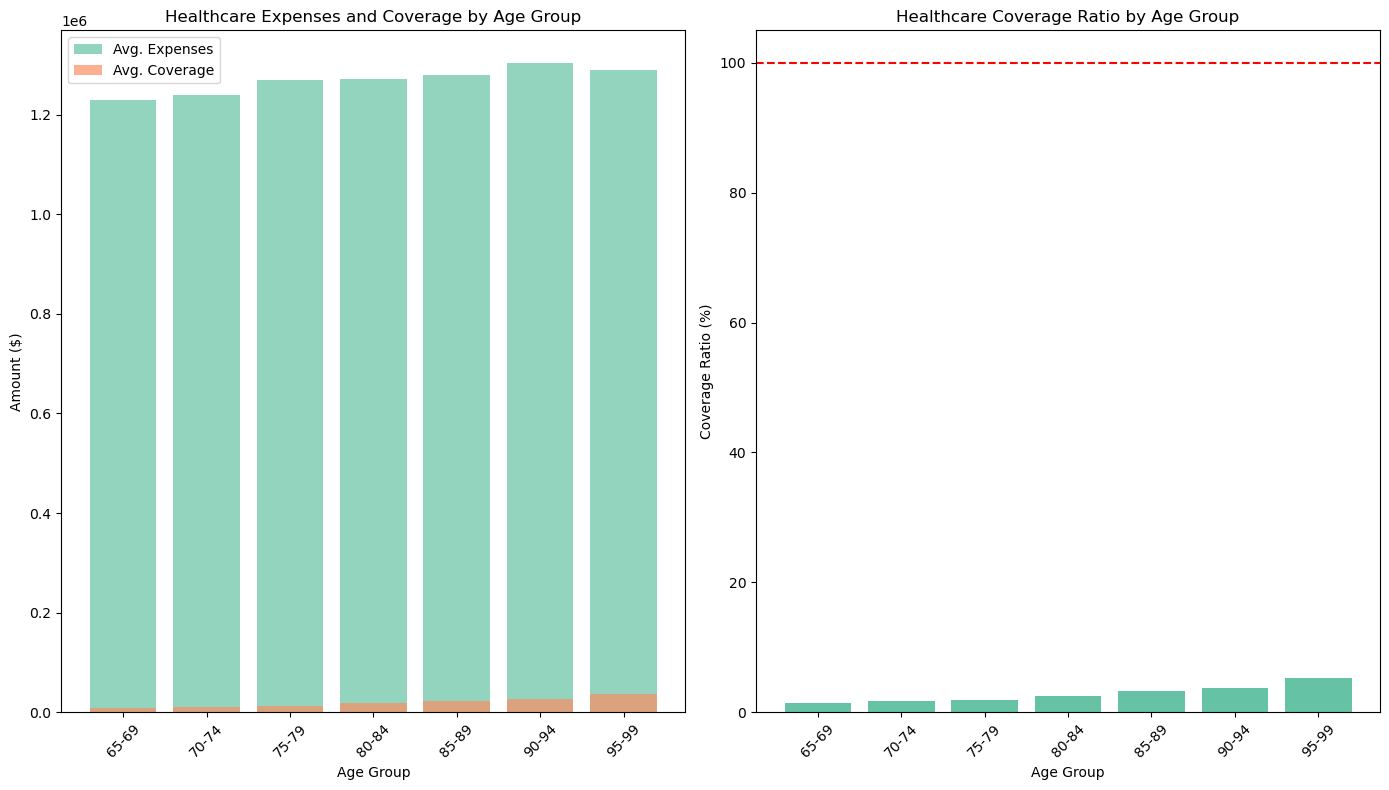

In [28]:
# Visualize healthcare metrics by age group
plt.figure(figsize=(14, 8))

# Plot average expenses and coverage by age group
plt.subplot(1, 2, 1)
plt.bar(age_group_stats['AGE_GROUP'], age_group_stats['HEALTHCARE_EXPENSES'], 
        label='Avg. Expenses', alpha=0.7)
plt.bar(age_group_stats['AGE_GROUP'], age_group_stats['HEALTHCARE_COVERAGE'], 
        label='Avg. Coverage', alpha=0.7)
plt.title('Healthcare Expenses and Coverage by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Amount ($)')
plt.legend()
plt.xticks(rotation=45)

# Plot coverage ratio by age group
plt.subplot(1, 2, 2)
plt.bar(age_group_stats['AGE_GROUP'], age_group_stats['COVERAGE_RATIO'] * 100)
plt.title('Healthcare Coverage Ratio by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Coverage Ratio (%)')
plt.xticks(rotation=45)
plt.axhline(y=100, color='r', linestyle='--', label='Full Coverage')

plt.tight_layout()
plt.show()

## Analysis by patient's demographics

Now, we will analyze healthcare gaps by demographic factors such as gender, race, and economic status.

In [29]:
# Analyze coverage gaps by gender
gender_stats = elderly_patients_pd.groupby('GENDER').agg({
    'HEALTHCARE_EXPENSES': 'mean',
    'HEALTHCARE_COVERAGE': 'mean',
    'COVERAGE_GAP': 'mean',
    'COVERAGE_RATIO': 'mean',
    'Id': 'count'
}).reset_index()

gender_stats.rename(columns={'Id': 'COUNT'}, inplace=True)

gender_stats

,GENDER,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,COVERAGE_GAP,COVERAGE_RATIO,COUNT
0,F,1238106.96,17291.97,1220815.00,0.02,17091
1,M,1302073.18,25902.21,1276170.98,0.04,21979


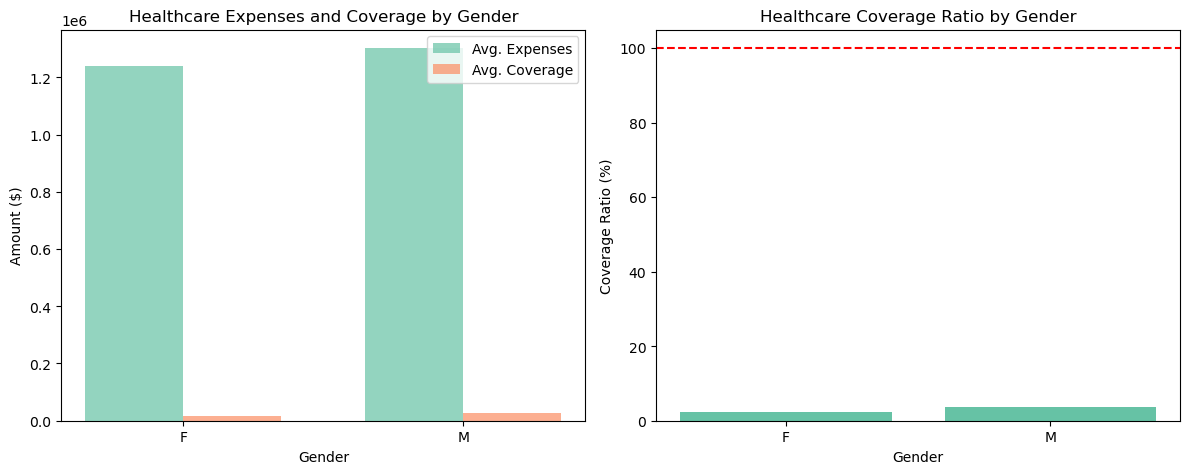

In [30]:
plt.figure(figsize=(12, 5))

# Plot expenses and coverage by gender
plt.subplot(1, 2, 1)
bar_width = 0.35
index = np.arange(len(gender_stats['GENDER']))
plt.bar(index, gender_stats['HEALTHCARE_EXPENSES'], bar_width, 
        label='Avg. Expenses', alpha=0.7)
plt.bar(index + bar_width, gender_stats['HEALTHCARE_COVERAGE'], bar_width, 
        label='Avg. Coverage', alpha=0.7)
plt.title('Healthcare Expenses and Coverage by Gender')
plt.xlabel('Gender')
plt.ylabel('Amount ($)')
plt.xticks(index + bar_width / 2, gender_stats['GENDER'])
plt.legend()

# Plot coverage ratio by gender
plt.subplot(1, 2, 2)
plt.bar(gender_stats['GENDER'], gender_stats['COVERAGE_RATIO'] * 100)
plt.title('Healthcare Coverage Ratio by Gender')
plt.xlabel('Gender')
plt.ylabel('Coverage Ratio (%)')
plt.axhline(y=100, color='r', linestyle='--')

plt.tight_layout()
plt.show()

In [31]:
# Analyze coverage gaps by race
race_stats = elderly_patients_pd.groupby('RACE').agg({
    'HEALTHCARE_EXPENSES': 'mean',
    'HEALTHCARE_COVERAGE': 'mean',
    'COVERAGE_GAP': 'mean',
    'COVERAGE_RATIO': 'mean',
    'Id': 'count'
}).reset_index()

race_stats.rename(columns={'Id': 'COUNT'}, inplace=True)

race_stats

,RACE,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,COVERAGE_GAP,COVERAGE_RATIO,COUNT
0,asian,1324640.66,23293.81,1301346.84,0.03,2910
1,black,1247707.55,23147.28,1224560.27,0.03,13576
2,native,1267757.31,24748.68,1243008.63,0.03,282
3,other,1329242.04,20618.31,1308623.74,0.03,51
4,white,1283532.05,21337.40,1262194.65,0.03,22251


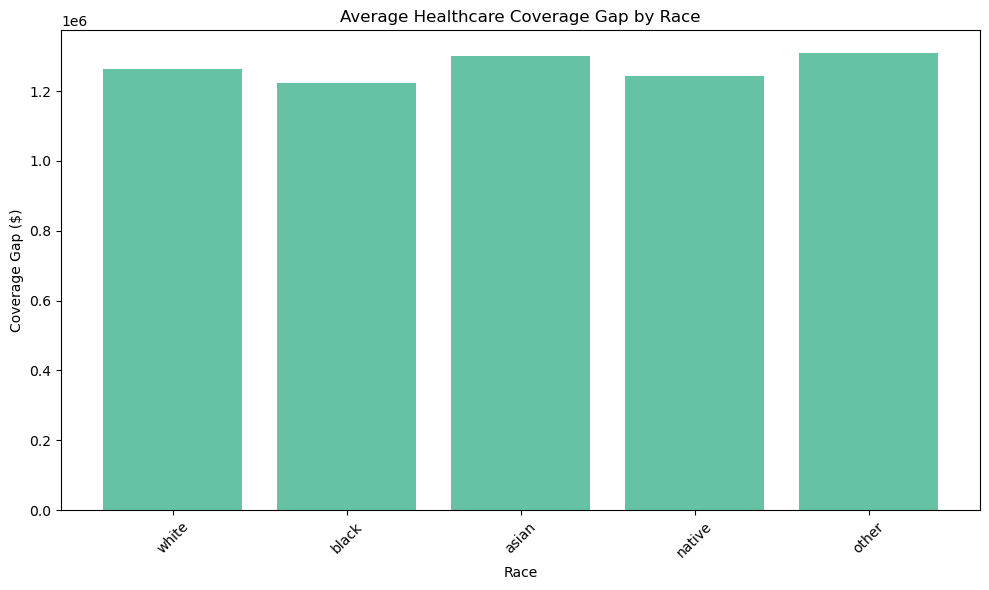

In [32]:
# Sort by population count
race_stats = race_stats.sort_values('COUNT', ascending=False)

plt.figure(figsize=(10, 6))

# Plot coverage gap by race
plt.bar(race_stats['RACE'], race_stats['COVERAGE_GAP'])
plt.title('Average Healthcare Coverage Gap by Race')
plt.xlabel('Race')
plt.ylabel('Coverage Gap ($)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Use KMeans clustering to identify patient groups

Now, we will use a big data technique to identify distinct groups of elderly patients based on their healthcare profiles.

In [33]:
# Prepare data for clustering
# Using normalized healthcare expenses and coverage
elderly_clustering_df = elderly_patients_pd[['Id', 'AGE', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE']].copy()

# Create a normalization function
def min_max_normalize(series):
    return (series - series.min()) / (series.max() - series.min())

# Normalize the numeric columns
elderly_clustering_df['AGE_NORM'] = min_max_normalize(elderly_clustering_df['AGE'])
elderly_clustering_df['EXPENSES_NORM'] = min_max_normalize(elderly_clustering_df['HEALTHCARE_EXPENSES'])
elderly_clustering_df['COVERAGE_NORM'] = min_max_normalize(elderly_clustering_df['HEALTHCARE_COVERAGE'])

In [34]:
# Prepare Spark DataFrame for clustering
spark_clustering_df = spark.createDataFrame(elderly_clustering_df)

# Define feature columns
feature_cols = ['AGE_NORM', 'EXPENSES_NORM', 'COVERAGE_NORM']

# Assemble features into a vector column
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
assembled_data = assembler.transform(spark_clustering_df)

# Train a KMeans model
k = 4  # Number of clusters
kmeans = KMeans().setK(k).setSeed(42).setFeaturesCol("features")
model = kmeans.fit(assembled_data)

# Make predictions
predictions = model.transform(assembled_data)

# Convert back to pandas for analysis
clusters_pd = predictions.select('Id', 'AGE', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'prediction').toPandas()
clusters_pd.rename(columns={'prediction': 'CLUSTER'}, inplace=True)
clusters_pd


25/05/01 12:44:03 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
25/05/01 12:44:03 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


,Id,AGE,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,CLUSTER
0,f1639046-ecb1-b409-21d3-85a7e8e23c81,67,59484.51,1455.08,2
1,f851859f-b0fe-8b36-9939-4276b96d302d,74,239428.05,12764.06,2
2,00e22b7e-70ae-e926-e0f6-4f3d8e30d019,71,1345863.62,3951.81,0
3,fc488d45-11b9-52d3-3c81-14dbd5dbc7dc,85,85562.87,4717.97,2
4,bc7d25d5-4bf2-2faa-92f3-e111fb97fbcf,96,1429312.17,16704.24,1
...,...,...,...,...,...
39065,88b9fe55-44a6-9237-75c8-4fcfec4a6f3d,95,1605632.70,5007.60,1
39066,0de6fede-45fe-521b-131b-a51ef48dac13,95,839609.30,1870.26,1
39067,485b315b-d575-9653-4bf5-30df6080a677,95,1344139.07,16129.24,1
39068,8e02420f-660a-f362-b25e-2852632fe78b,95,1780466.80,6606.91,1


In [35]:
# Analyze the clusters
cluster_stats = clusters_pd.groupby('CLUSTER').agg({
    'AGE': 'mean',
    'HEALTHCARE_EXPENSES': 'mean',
    'HEALTHCARE_COVERAGE': 'mean',
    'Id': 'count'
}).reset_index()

cluster_stats['COVERAGE_GAP'] = cluster_stats['HEALTHCARE_EXPENSES'] - cluster_stats['HEALTHCARE_COVERAGE']
cluster_stats['COVERAGE_RATIO'] = cluster_stats['HEALTHCARE_COVERAGE'] / cluster_stats['HEALTHCARE_EXPENSES']
cluster_stats.rename(columns={'Id': 'COUNT'}, inplace=True)

print("Healthcare Clusters Among Elderly Patients:")
cluster_stats

Healthcare Clusters Among Elderly Patients:


,CLUSTER,AGE,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,COUNT,COVERAGE_GAP,COVERAGE_RATIO
0,0,73.89,1443303.73,11020.67,11812,1432283.06,0.01
1,1,91.74,1504407.74,15537.15,19523,1488870.59,0.01
2,2,85.91,226195.81,16729.91,6551,209465.90,0.07
3,3,93.62,1586222.88,271736.52,1184,1314486.36,0.17


<Figure size 1200x1000 with 0 Axes>

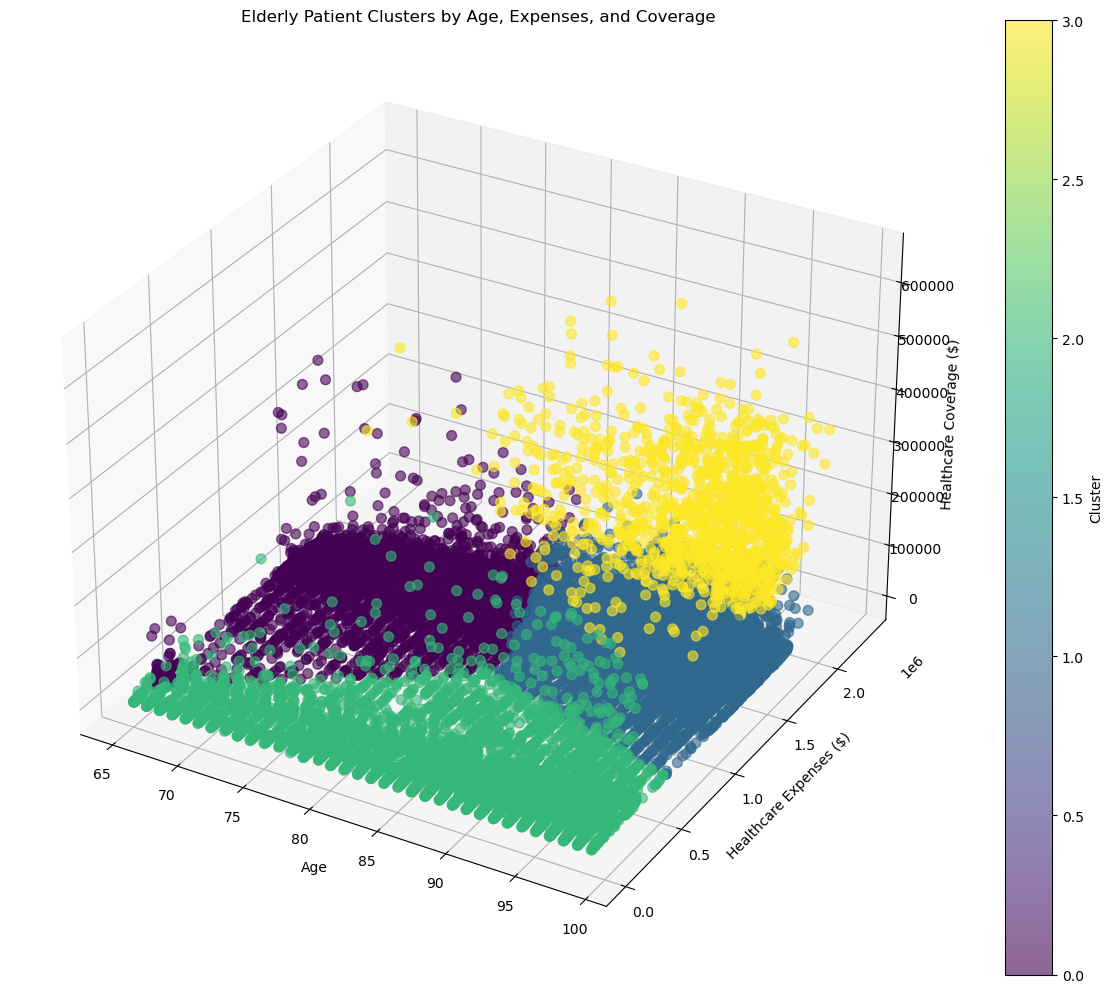

In [36]:
# Visualize the clusters
plt.figure(figsize=(12, 10))

# Create a 3D scatter plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Create scatter plot with cluster colors
scatter = ax.scatter(clusters_pd['AGE'], 
                    clusters_pd['HEALTHCARE_EXPENSES'], 
                    clusters_pd['HEALTHCARE_COVERAGE'],
                    c=clusters_pd['CLUSTER'], 
                    cmap='viridis', 
                    s=50, 
                    alpha=0.6)

# Add labels and title
ax.set_xlabel('Age')
ax.set_ylabel('Healthcare Expenses ($)')
ax.set_zlabel('Healthcare Coverage ($)')
ax.set_title('Elderly Patient Clusters by Age, Expenses, and Coverage')

# Add a color bar
cbar = plt.colorbar(scatter)
cbar.set_label('Cluster')

plt.tight_layout()
plt.show()

## Analyze high-need areas

Now, we will analyze counties with the highest healthcare gaps for elderly patients.

In [37]:
# Analyze coverage gaps by county
county_stats = elderly_patients_pd.groupby('COUNTY').agg({
    'HEALTHCARE_EXPENSES': 'mean',
    'HEALTHCARE_COVERAGE': 'mean',
    'COVERAGE_GAP': 'mean',
    'COVERAGE_RATIO': 'mean',
    'Id': 'count'
}).reset_index()

county_stats.rename(columns={'Id': 'COUNT'}, inplace=True)
county_stats = county_stats.sort_values('COVERAGE_GAP', ascending=False)

# Display only counties with significant elderly populations
significant_counties = county_stats[county_stats['COUNT'] >= 20].head(10)
print("Counties with Highest Coverage Gaps for Elderly Patients:")
significant_counties

Counties with Highest Coverage Gaps for Elderly Patients:


,COUNTY,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,COVERAGE_GAP,COVERAGE_RATIO,COUNT
8,Charles County,1372248.92,17976.06,1354272.86,0.02,844
17,Queen Anne's County,1372092.75,17876.68,1354216.07,0.01,167
13,Howard County,1358860.10,21001.03,1337859.07,0.02,2208
23,Worcester County,1341781.53,19105.52,1322676.01,0.02,233
15,Montgomery County,1342094.87,21368.44,1320726.43,0.02,7611
4,Calvert County,1335592.08,16385.86,1319206.22,0.02,304
1,Anne Arundel County,1335324.20,21224.21,1314100.00,0.03,3991
10,Frederick County,1332173.70,24844.03,1307329.67,0.03,1316
6,Carroll County,1323888.88,21867.32,1302021.56,0.03,600
16,Prince George's County,1301384.62,23517.36,1277867.26,0.03,6963


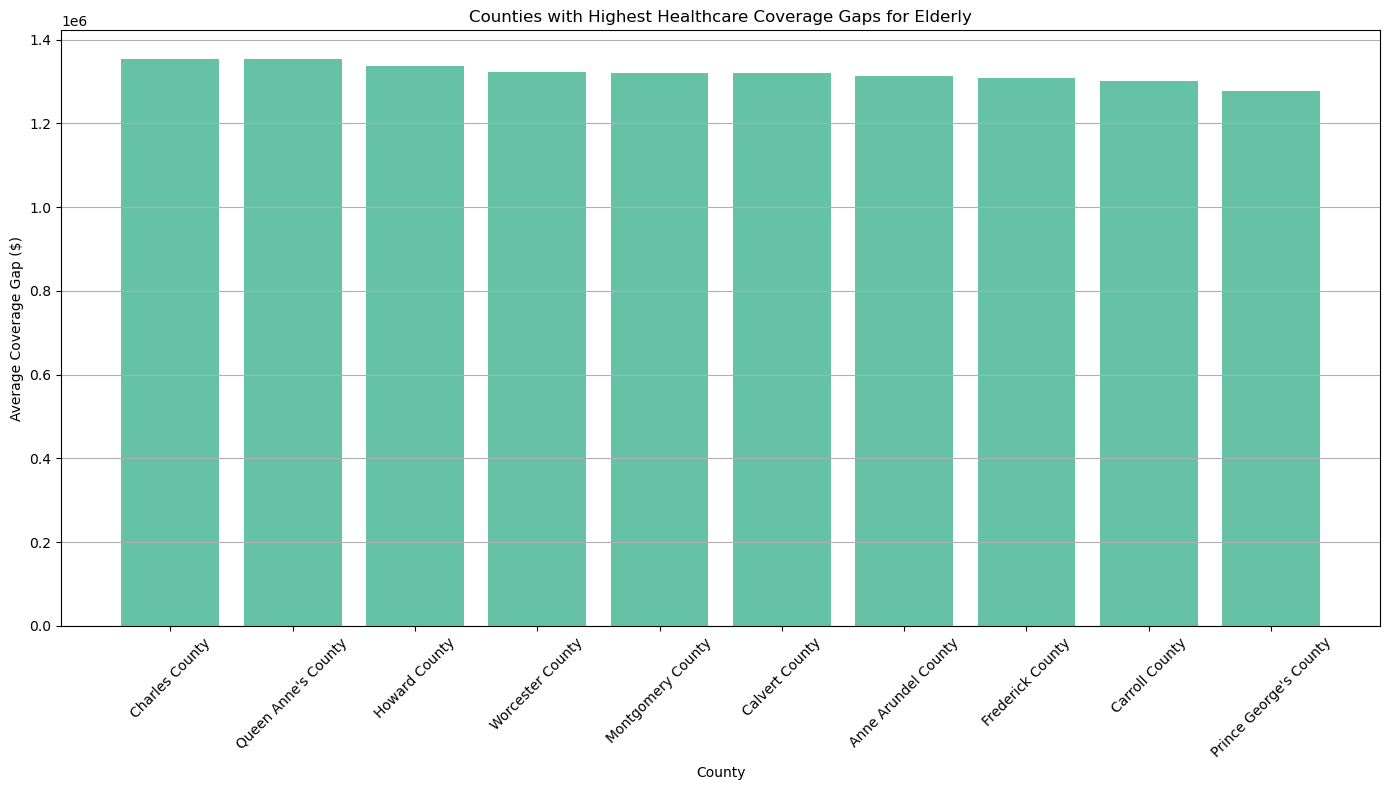

In [38]:
# Visualize top counties by coverage gap
plt.figure(figsize=(14, 8))
plt.bar(significant_counties['COUNTY'], significant_counties['COVERAGE_GAP'])
plt.title('Counties with Highest Healthcare Coverage Gaps for Elderly')
plt.xlabel('County')
plt.ylabel('Average Coverage Gap ($)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()